# Evidencia Modulo 7 Deep Learning
- Alumno: Manuel Bajos Rivera
- Matricula: A01711581

## 1. Obtener el dataset de Kaggle de imagenes
Se descarga el dataset mediante kagglehub y se guarda en cache.

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hadiepratamatulili/anime-vs-cartoon-vs-human")

print("Path to dataset files:", path)

/Users/manuelbajos/Documents/tec/semestres/Septimo/ConcentracionIA/ML/DL/evidencia/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/manuelbajos/.cache/kagglehub/datasets/hadiepratamatulili/anime-vs-cartoon-vs-human/versions/2


## 2. Configuracion y carga de rutas
Se fija la semilla para reproducibilidad y se arma un DataFrame con la ruta y la clase de cada imagen. Versiones: TensorFlow 2.20.0 / Keras 3 (ver `requirements.txt`), compatibles con macOS, Linux y Windows.

In [2]:
import hashlib
import os
import random
import sys
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

# Raiz del repositorio (donde esta requirements.txt). Las rutas se calculan desde ahi
# para que el notebook funcione sin importar desde que carpeta se ejecute.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

TensorFlow: 2.20.0 | Keras: 3.15.1
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
DATA_DIR = Path(path) / "Data"
CLASSES = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())

df = pd.DataFrame(
    [{"filepath": str(f), "label": c}
     for c in CLASSES for f in sorted((DATA_DIR / c).iterdir()) if f.is_file()]
)
print("Clases:", CLASSES)
print("Total de imagenes:", len(df))

df.info()

Clases: ['anime', 'cartoon', 'human']
Total de imagenes: 8917
<class 'pandas.DataFrame'>
RangeIndex: 8917 entries, 0 to 8916
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filepath  8917 non-null   str  
 1   label     8917 non-null   str  
dtypes: str(2)
memory usage: 1.2 MB


## 3. Analisis exploratorio de datos (EDA)
Antes de modelar se revisa balance de clases, integridad de archivos, resolucion, modo de color, duplicados y estadisticos de color. Estos hallazgos determinan el preprocesamiento.

In [4]:
def read_meta(fp):
    """Lee dimensiones, modo y formato, y verifica que el archivo no este corrupto."""
    try:
        with Image.open(fp) as im:
            width, height, mode, fmt = *im.size, im.mode, im.format
            im.verify()
        return width, height, mode, fmt, True
    except Exception:
        return None, None, None, None, False

df[["width", "height", "mode", "format", "ok"]] = [read_meta(f) for f in df["filepath"]]
df["ok"] = df["ok"].astype(bool)
df[["width", "height"]] = df[["width", "height"]].astype("Int64")
df["size_kb"] = df["filepath"].map(os.path.getsize) / 1024

print("Imagenes corruptas:", (~df["ok"]).sum())
df.head()

Imagenes corruptas: 0


,filepath,label,width,height,mode,format,ok,size_kb
0,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,63,63,RGB,JPEG,True,3.526367
1,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,74,74,RGB,JPEG,True,4.679688
2,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,51,51,RGB,JPEG,True,3.219727
3,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,54,54,RGB,JPEG,True,3.088867
4,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,116,116,RGB,JPEG,True,9.548828


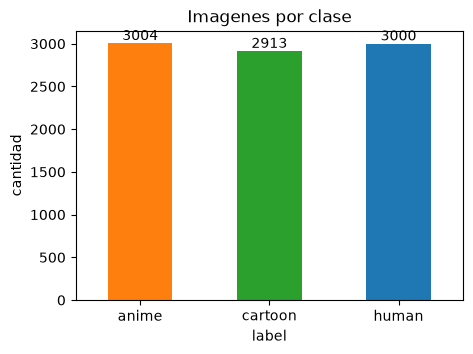

In [5]:
counts = df["label"].value_counts().reindex(CLASSES)
ax = counts.plot.bar(figsize=(5, 3.5), color=["tab:orange", "tab:green", "tab:blue"])
ax.bar_label(ax.containers[0])
ax.set_title("Imagenes por clase")
ax.set_ylabel("cantidad")
plt.xticks(rotation=0)
plt.show()

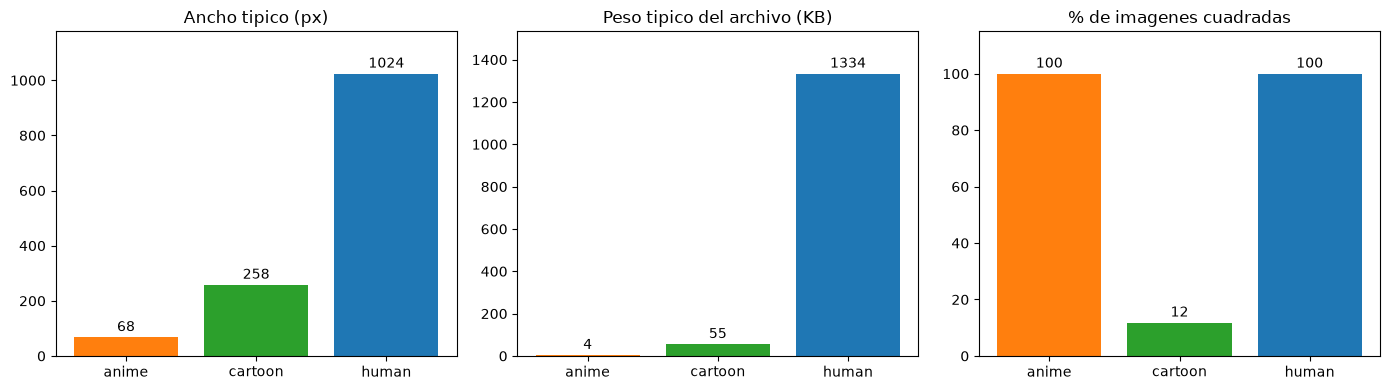

width               height               aspect              size_kb  \
          min  median   max    min  median   max    min median   max     min   
label                                                                          
anime      25    68.0   189     25    68.0   189   1.00   1.00  1.02    1.21   
cartoon    74   258.0   519     77   180.0   315   0.37   1.34  5.35    2.95   
human    1024  1024.0  1024   1024  1024.0  1024   1.00   1.00  1.00  595.76   

                           
          median      max  
label                      
anime       4.21    23.92  
cartoon    55.44   133.23  
human    1333.76  2057.71

In [6]:
# Resolucion y peso de archivo por clase: valor tipico (mediana) de cada clase
df["aspect"] = (df["width"] / df["height"]).astype(float)
df["square"] = (df["aspect"] - 1).abs() < 0.05   # casi cuadrada (+-5%)
COLORS = {"anime": "tab:orange", "cartoon": "tab:green", "human": "tab:blue"}

summary = pd.DataFrame({
    "Ancho tipico (px)": df.groupby("label")["width"].median().astype(float),
    "Peso tipico del archivo (KB)": df.groupby("label")["size_kb"].median(),
    "% de imagenes cuadradas": df.groupby("label")["square"].mean() * 100,
}).reindex(CLASSES)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, summary.columns):
    bars = ax.bar(CLASSES, summary[col], color=[COLORS[c] for c in CLASSES])
    ax.bar_label(bars, fmt="%.0f", padding=2)
    ax.set_title(col)
    ax.set_ylim(0, summary[col].max() * 1.15)
plt.tight_layout()
plt.show()

display(df.groupby("label")[["width", "height", "aspect", "size_kb"]].agg(["min", "median", "max"]).round(2))

In [7]:
# Modo de color y formato por clase
display(pd.crosstab(df["label"], df["mode"]))
display(pd.crosstab(df["label"], df["format"]))

# Las imagenes RGBA / P: tienen transparencia real? (si no, convert("RGB") es seguro)
def has_transparency(fp):
    with Image.open(fp) as im:
        alpha = np.asarray(im.convert("RGBA"))[..., 3]
    return bool((alpha < 255).any())

non_rgb = df[df["mode"] != "RGB"]
n_transp = sum(has_transparency(f) for f in non_rgb["filepath"])
print(f"Imagenes no RGB: {len(non_rgb)} | con transparencia real: {n_transp}")

mode,P,RGB,RGBA
label,,,
anime,0,3004,0
cartoon,74,653,2186
human,0,3000,0


format,JPEG,PNG
label,,
anime,3004,0
cartoon,653,2260
human,0,3000


Imagenes no RGB: 2260 | con transparencia real: 0


In [8]:
# Duplicados exactos (mismo contenido de archivo)
df["md5"] = [hashlib.md5(Path(f).read_bytes()).hexdigest() for f in df["filepath"]]

dups = df[df.duplicated("md5", keep=False)]
print("Imagenes involucradas en duplicados:", len(dups), "| grupos:", dups["md5"].nunique())
print("Grupos que mezclan clases:", (dups.groupby("md5")["label"].nunique() > 1).sum())

extra = df[df.duplicated("md5", keep="first")]
print("\nImagenes sobrantes por clase si se deduplica:")
print(extra["label"].value_counts())

df_unique = df.drop_duplicates("md5").reset_index(drop=True)
print("\nConteo por clase tras deduplicar:")
print(df_unique["label"].value_counts())

Imagenes involucradas en duplicados: 712 | grupos: 329
Grupos que mezclan clases: 0

Imagenes sobrantes por clase si se deduplica:
label
anime    383
Name: count, dtype: int64

Conteo por clase tras deduplicar:
label
human      3000
cartoon    2913
anime      2621
Name: count, dtype: int64


Tamano de los grupos duplicados: {2: 286, 3: 36, 4: 3, 5: 4}


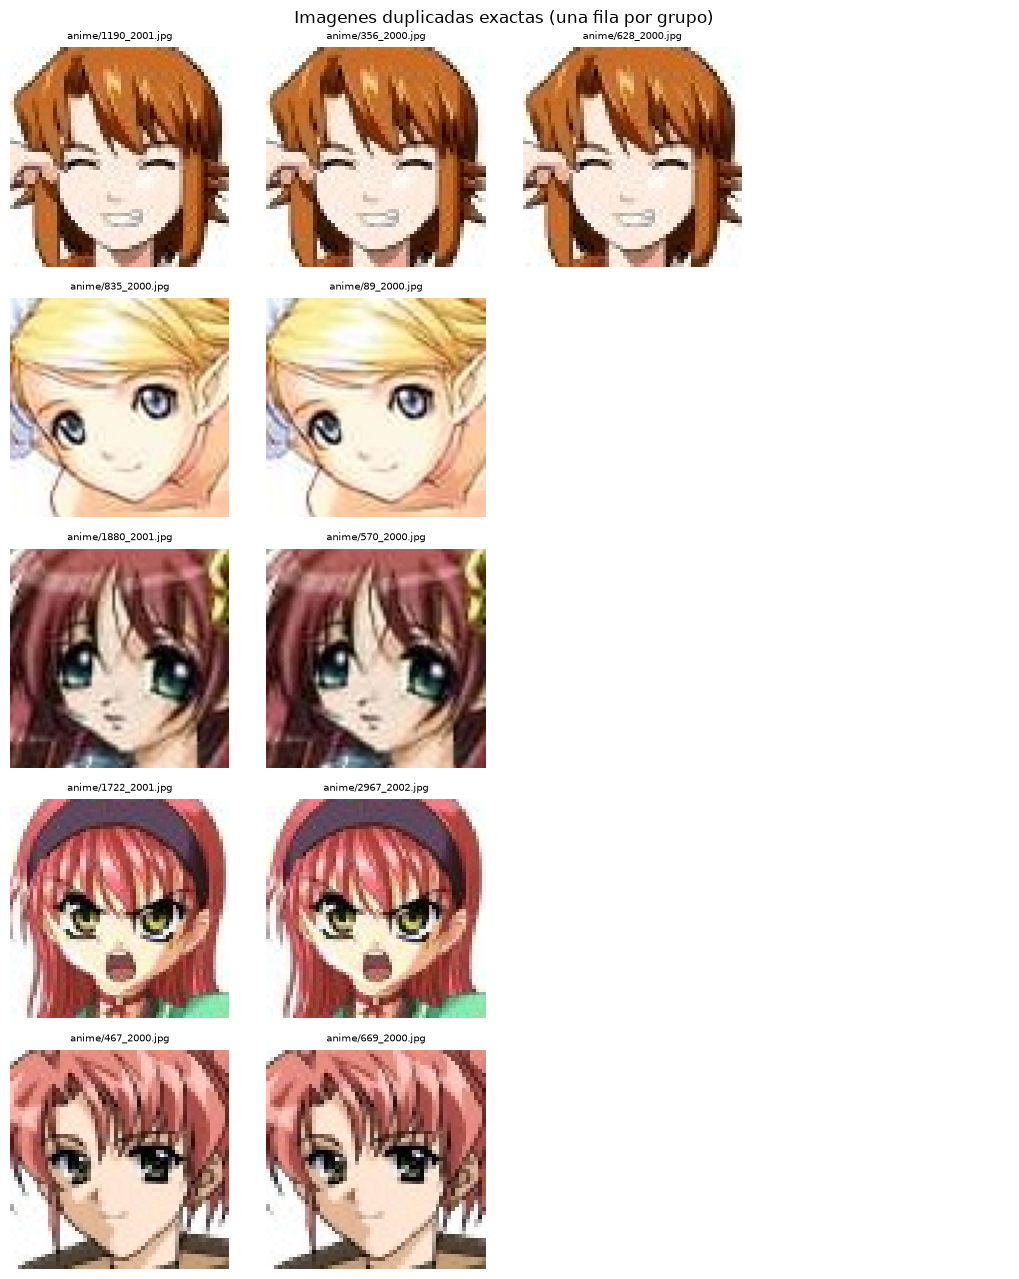

In [9]:
# Ejemplos de grupos duplicados: cada fila es un grupo, cada columna una copia
N_GROUPS, MAX_COPIES = 5, 4
groups = dups.groupby("md5").size().sort_values(ascending=False)
print("Tamano de los grupos duplicados:", groups.value_counts().sort_index().to_dict())

sample_md5 = groups.sample(N_GROUPS, random_state=SEED).index
fig, axes = plt.subplots(N_GROUPS, MAX_COPIES, figsize=(2.6 * MAX_COPIES, 2.6 * N_GROUPS))
for i, h in enumerate(sample_md5):
    copies = dups[dups["md5"] == h].head(MAX_COPIES)
    for j in range(MAX_COPIES):
        ax = axes[i, j]
        ax.axis("off")
        if j < len(copies):
            r = copies.iloc[j]
            with Image.open(r["filepath"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{r['label']}/{Path(r['filepath']).name}", fontsize=7)
plt.suptitle("Imagenes duplicadas exactas (una fila por grupo)")
plt.tight_layout()
plt.show()

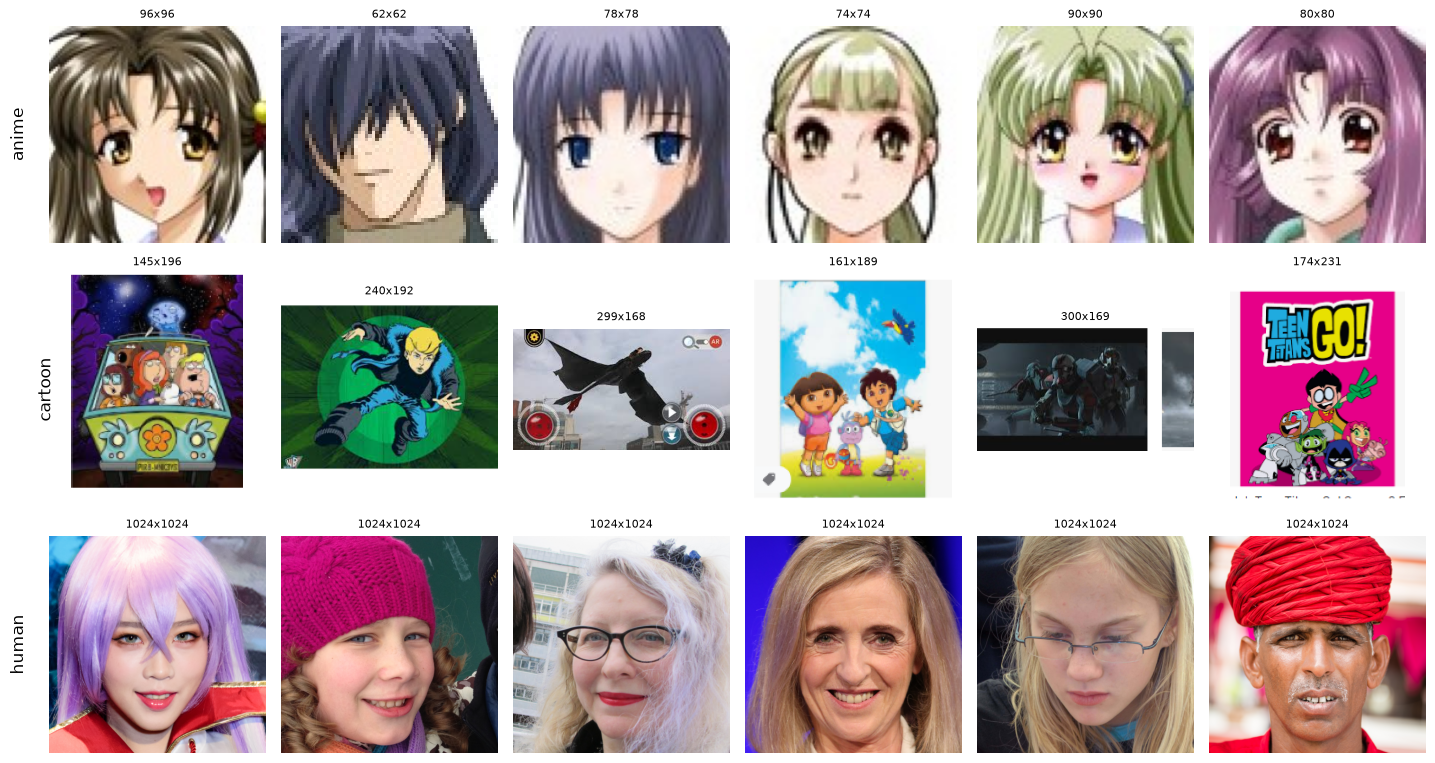

In [10]:
# Muestra aleatoria de imagenes por clase (el titulo indica la resolucion original)
N = 6
fig, axes = plt.subplots(len(CLASSES), N, figsize=(2.4 * N, 2.6 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, (_, r) in enumerate(df[df["label"] == c].sample(N, random_state=SEED).iterrows()):
        with Image.open(r["filepath"]) as im:
            axes[i, j].imshow(im.convert("RGB"))
        axes[i, j].set_title(f"{r['width']}x{r['height']}", fontsize=8)
        axes[i, j].axis("off")
    axes[i, 0].text(-0.1, 0.5, c, transform=axes[i, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=12)
plt.tight_layout()
plt.show()

,R,G,B,std
label,,,,
anime,0.637497,0.544931,0.513575,0.276612
cartoon,0.609673,0.575152,0.549934,0.264825
human,0.520899,0.424424,0.377492,0.239252


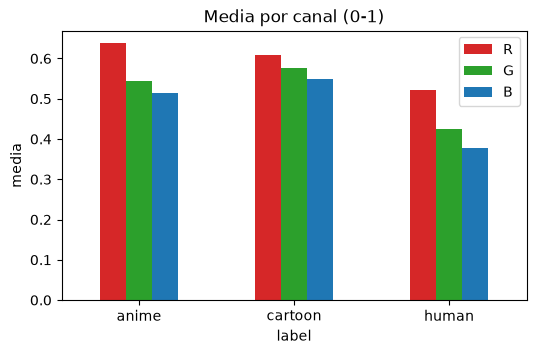

In [11]:
# Estadisticos de color sobre una muestra de 300 imagenes por clase, a 64x64
rows = []
for c in CLASSES:
    for f in df[df["label"] == c].sample(300, random_state=SEED)["filepath"]:
        with Image.open(f) as im:
            x = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32) / 255
        rows.append({"label": c, "R": x[..., 0].mean(), "G": x[..., 1].mean(),
                     "B": x[..., 2].mean(), "std": x.std()})

color_stats = pd.DataFrame(rows).groupby("label").mean()
display(color_stats)
color_stats[["R", "G", "B"]].plot.bar(color=["tab:red", "tab:green", "tab:blue"], figsize=(6, 3.5))
plt.title("Media por canal (0-1)")
plt.ylabel("media")
plt.xticks(rotation=0)
plt.show()

### Conclusiones del EDA

- **Balance:** clases casi balanceadas (2913 a 3004 por clase; tras deduplicar, 2621 a 3000), por lo que accuracy es una métrica adecuada para comparar modelos. Como la exactitud global puede ocultar un mal desempeño en una clase, se reportan además precision, recall y F1 por clase, el F1 macro y la matriz de confusión (sección 5).
- **Integridad:** no hay archivos corruptos.
- **Resolución (riesgo de atajo):** anime son miniaturas (25–189 px, ~5 KB), cartoon es intermedio (74–519 px, ~50 KB) y human siempre es 1024×1024 (~1.3 MB). Un modelo podría clasificar por nitidez o resolución y no por contenido. Se mitiga redimensionando todo a un tamaño único y con aumento de datos.
- **Contenido:** anime y human son retratos de rostros recortados, mientras que cartoon incluye personajes de cuerpo completo, escenas y capturas con márgenes. El modelo puede apoyarse en la composición. Hay que revisar las imágenes mal clasificadas, por ejemplo humanos con estética anime.
- **Canales:** cartoon mezcla RGB (653), RGBA (2186) y paleta P (74). Ninguna imagen tiene transparencia real, así que `convert("RGB")` no altera el contenido.
- **Relación de aspecto:** anime y human son cuadradas; cartoon va de 0.37 a 5.35. Redimensionar directo a cuadrado deforma las cartoon, y hay que decidir entre estirar o rellenar (padding).
- **Duplicados:** hay 383 imágenes duplicadas exactas, todas de la clase anime y ninguna entre clases. Se eliminan **antes** de dividir en train/val/test para evitar fuga de datos. Tras deduplicar: human 3000, cartoon 2913, anime 2621 (desbalance leve).
- **Color:** human es en promedio más oscura (media de R, G y B de 0.52, 0.42 y 0.38) que anime (0.64, 0.54, 0.51) y cartoon (0.61, 0.58, 0.55). Es otra señal que el modelo podría aprovechar.
- **Normalización:** `Rescaling(1/255)` dentro de la CNN propia. EfficientNet incluye su propio preprocesamiento y espera valores en [0, 255].


## 4. ETL: transformacion y carga
Con base en el EDA se transforman los datos: se parten las rutas sin duplicados en entrenamiento, validacion y prueba (70/15/15, estratificado), y cada imagen se convierte a RGB y se deja en 128x128. Los arreglos resultantes (`uint8`) se guardan en una cache local para no volver a decodificar las imagenes originales.

`RESIZE_MODE` controla como se llega a un cuadrado: `"pad"` conserva la proporcion y rellena con el color del borde, y `"stretch"` estira la imagen. Se empieza con `"pad"` y despues se compara con `"stretch"`, ya que el padding puede introducir un atajo (las cartoon no cuadradas tendrian barras y las otras clases no). El preprocesado de cada imagen vive en `src/preprocesamiento.py`, compartido con la interfaz web para que el modelo reciba siempre lo mismo que vio al entrenar. La division entre 255 se hace dentro del modelo, y el aumento de datos solo en entrenamiento.

In [12]:
from concurrent.futures import ThreadPoolExecutor

from sklearn.model_selection import train_test_split

# Preprocesado compartido con la interfaz web (src/preprocesamiento.py)
from src.preprocesamiento import CLASSES as MODEL_CLASSES, IMG_SIZE, preprocess as preprocess_image

RESIZE_MODE = "pad"   # "pad": conserva la proporcion y rellena | "stretch": estira a cuadrado
CACHE_DIR = ROOT / "cache" / f"{RESIZE_MODE}_{IMG_SIZE}"
assert CLASSES == MODEL_CLASSES, "el orden de las clases difiere del de src/preprocesamiento.py"
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
print("Modo:", RESIZE_MODE, "| Tamano:", IMG_SIZE, "| Cache:", CACHE_DIR.relative_to(ROOT))
print("Clases -> indice:", CLASS_TO_IDX)

Modo: pad | Tamano: 128 | Cache: cache/pad_128
Clases -> indice: {'anime': 0, 'cartoon': 1, 'human': 2}


In [13]:
# Particion estratificada 70/15/15 sobre las imagenes sin duplicados
df_unique["y"] = df_unique["label"].map(CLASS_TO_IDX)

train_df, rest_df = train_test_split(
    df_unique, test_size=0.30, stratify=df_unique["y"], random_state=SEED)
val_df, test_df = train_test_split(
    rest_df, test_size=0.50, stratify=rest_df["y"], random_state=SEED)
splits = {"train": train_df, "val": val_df, "test": test_df}

# Ninguna imagen (por contenido) puede estar en dos particiones
hashes = {name: set(d["md5"]) for name, d in splits.items()}
assert not (hashes["train"] & hashes["val"] or hashes["train"] & hashes["test"]
            or hashes["val"] & hashes["test"]), "hay fuga de datos entre particiones"

display(pd.DataFrame({name: d["label"].value_counts() for name, d in splits.items()})
        .reindex(CLASSES).assign(total=lambda t: t.sum(axis=1)))

,train,val,test,total
label,,,,
anime,1834,393,394,2621
cartoon,2039,437,437,2913
human,2100,450,450,3000


In [14]:
def preprocess(fp, size=IMG_SIZE, mode=RESIZE_MODE):
    """Abre el archivo y lo transforma con la misma funcion que usa la interfaz web."""
    with Image.open(fp) as im:
        return preprocess_image(im, size, mode)


def build_split(name, d, mode=RESIZE_MODE):
    """Devuelve (X, y) de una particion con el modo de redimensionado indicado; si ya esta en cache la carga del disco."""
    cache_dir = ROOT / "cache" / f"{mode}_{IMG_SIZE}"
    out = cache_dir / f"{name}.npz"
    if out.exists():
        z = np.load(out)
        return z["X"], z["y"]
    with ThreadPoolExecutor() as pool:
        X = np.stack(list(pool.map(lambda fp: preprocess(fp, IMG_SIZE, mode), d["filepath"])))
    y = d["y"].to_numpy(np.int64)
    cache_dir.mkdir(parents=True, exist_ok=True)
    np.savez(out, X=X, y=y)
    return X, y


data = {name: build_split(name, d) for name, d in splits.items()}
for name, (X, y) in data.items():
    print(f"{name:5s} X={X.shape} {X.dtype} | y={y.shape} | clases={np.bincount(y).tolist()}")

train X=(5973, 128, 128, 3) uint8 | y=(5973,) | clases=[1834, 2039, 2100]
val   X=(1280, 128, 128, 3) uint8 | y=(1280,) | clases=[393, 437, 450]
test  X=(1281, 128, 128, 3) uint8 | y=(1281,) | clases=[394, 437, 450]


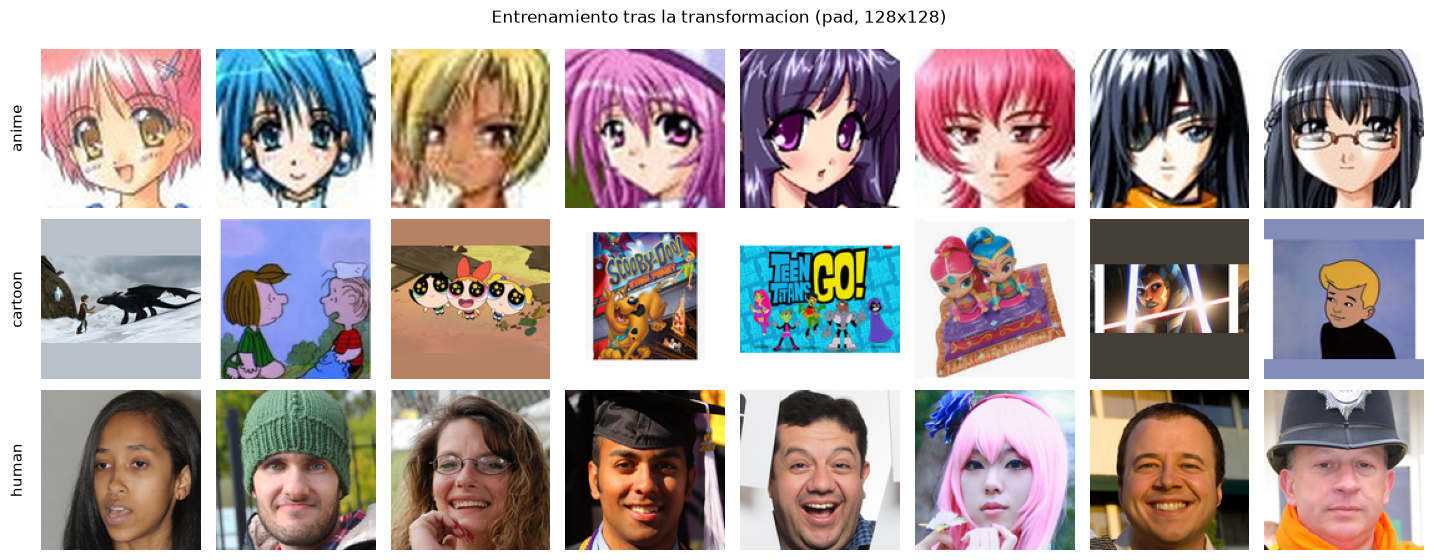

Rango de pixeles: 0 - 255 | memoria train: 294 MB


In [15]:
# Verificacion visual: imagenes de entrenamiento ya transformadas
X_train, y_train = data["train"]
rng = np.random.default_rng(SEED)
N = 8
fig, axes = plt.subplots(len(CLASSES), N, figsize=(1.8 * N, 1.9 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    idx = rng.choice(np.where(y_train == CLASS_TO_IDX[c])[0], N, replace=False)
    for j, k in enumerate(idx):
        axes[i, j].imshow(X_train[k])
        axes[i, j].axis("off")
    axes[i, 0].text(-0.1, 0.5, c, transform=axes[i, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=11)
plt.suptitle(f"Entrenamiento tras la transformacion ({RESIZE_MODE}, {IMG_SIZE}x{IMG_SIZE})")
plt.tight_layout()
plt.show()

print("Rango de pixeles:", X_train.min(), "-", X_train.max(), "| memoria train: %.0f MB" % (X_train.nbytes / 1e6))

## 5. Metricas de evaluacion
Las clases estan casi balanceadas, por lo que la exactitud (accuracy) es adecuada para comparar los modelos. Sin embargo, la exactitud global puede ocultar un desempeno deficiente en una clase particular, asi que ademas se reportan:

- **Precision por clase:** de las imagenes que el modelo asigno a una clase, cuantas realmente son de esa clase.
- **Recall (sensibilidad) por clase:** de las imagenes que realmente son de una clase, cuantas encontro el modelo.
- **F1 por clase:** media armonica de precision y recall, `2 * P * R / (P + R)`. Es alto solo si ambas lo son.
- **F1 macro:** promedio simple de los tres F1 por clase, `(F1_anime + F1_cartoon + F1_human) / 3`. Cada clase pesa lo mismo sin importar su tamano, por lo que una clase debil baja el resultado. Es un solo numero para comparar modelos, mientras que el F1 por clase muestra donde falla.
- **Matriz de confusion:** muestra que clases se confunden entre si.

La funcion `evaluate` calcula todo esto a partir de las etiquetas reales y las predichas, y se usa con cada modelo en validacion y en prueba.

In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score


LABELS = list(range(len(CLASSES)))


def evaluate(y_true, y_pred, title=""):
    """Imprime accuracy, F1 macro y el reporte por clase, y grafica la matriz de confusion."""
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)
    print(f"Accuracy: {acc:.4f} | F1 macro: {f1_macro:.4f}\n")
    print(classification_report(y_true, y_pred, labels=LABELS, target_names=CLASSES, digits=3, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Real")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return {"accuracy": acc, "f1_macro": f1_macro}

## 6. Modelo base: CNN propia
Se parte de una red convolucional sencilla, sin regularizacion ni aumento de datos, para tener un punto de comparacion claro. Cada mejora posterior (aumento de datos, Dropout, BatchNorm, etc.) se prueba por separado para poder explicar cual funciono y por que.

- **Entrada:** imagenes RGB de 128x128, escaladas a [0, 1] con una capa `Rescaling(1/255)` dentro del modelo.
- **Extractor de caracteristicas:** tres bloques `Conv2D` (32, 64 y 128 filtros de 3x3, activacion ReLU) seguidos de `MaxPooling2D`. Las primeras capas detectan bordes y texturas, y las ultimas formas mas complejas.
- **Clasificador:** `Flatten`, una capa densa de 128 neuronas con ReLU y una capa de salida de 3 neuronas con `softmax`, que da la probabilidad de cada clase.
- **Entrenamiento:** optimizador Adam (tasa de aprendizaje 0.001), perdida `sparse_categorical_crossentropy` (las etiquetas son enteros), lotes de 32 imagenes y 15 epocas.

El modelo y su historial de entrenamiento se guardan en la carpeta `modelos/`. Si ya existen, la celda los carga en lugar de volver a entrenar (se puede forzar con `RETRAIN = True`). Se evalua en validacion y en prueba. El conjunto de prueba solo se usa para reportar el desempeno final de cada modelo, nunca para decidir ajustes.

In [17]:
import json

BATCH_SIZE = 32
EPOCHS = 15
MODELS_DIR = ROOT / "modelos"
MODEL_NAME = f"cnn_base_{RESIZE_MODE}"


def make_ds(X, y, shuffle=False):
    """Dataset de tf.data: (imagen uint8, etiqueta) en batches."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_ds(*data["train"], shuffle=True)
val_ds = make_ds(*data["val"])


def build_cnn_base(dropout=0.0, name="cnn_base"):
    """CNN sencilla, punto de partida. Sin regularizacion ni aumento de datos si dropout=0."""
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        keras.layers.Rescaling(1 / 255),
        keras.layers.Conv2D(32, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(128, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        *([keras.layers.Dropout(dropout)] if dropout else []),
        keras.layers.Dense(len(CLASSES), activation="softmax"),
    ], name=name)


model = build_cnn_base()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
MODELS_DIR.mkdir(exist_ok=True)
model_path = MODELS_DIR / f"{MODEL_NAME}.keras"
history_path = MODELS_DIR / f"{MODEL_NAME}_history.json"
RETRAIN = False   # True: volver a entrenar aunque ya exista el modelo guardado

if model_path.exists() and not RETRAIN:
    model = keras.models.load_model(model_path)
    history = json.loads(history_path.read_text())
    print("Modelo cargado de", model_path.relative_to(ROOT))
else:
    fit = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, shuffle=False, verbose=2)
    history = fit.history
    model.save(model_path)
    history_path.write_text(json.dumps(history))
    print("Modelo guardado en", model_path.relative_to(ROOT))

Modelo cargado de modelos/cnn_base_pad.keras


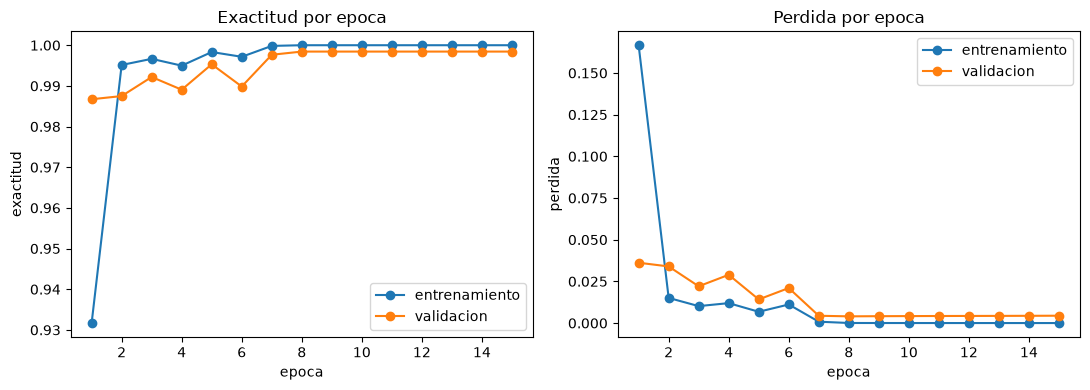

In [19]:
# Curvas de aprendizaje: entrenamiento vs validacion
epochs_range = range(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["accuracy", "loss"], ["Exactitud", "Perdida"]):
    ax.plot(epochs_range, history[metric], marker="o", label="entrenamiento")
    ax.plot(epochs_range, history[f"val_{metric}"], marker="o", label="validacion")
    ax.set_title(f"{title} por epoca")
    ax.set_xlabel("epoca")
    ax.set_ylabel(title.lower())
    ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "curvas_cnn_base.png", dpi=200, bbox_inches="tight")
plt.show()

Accuracy: 0.9984 | F1 macro: 0.9985

              precision    recall  f1-score   support

       anime      1.000     1.000     1.000       393
     cartoon      0.998     0.998     0.998       437
       human      0.998     0.998     0.998       450

    accuracy                          0.998      1280
   macro avg      0.998     0.998     0.998      1280
weighted avg      0.998     0.998     0.998      1280



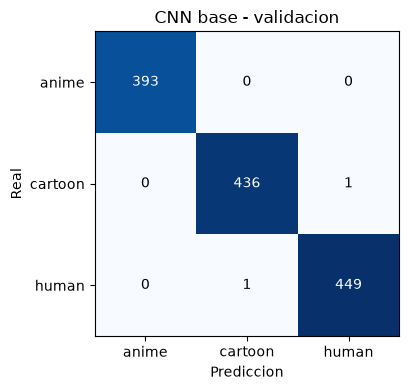

In [20]:
# Evaluacion de la CNN base en validacion
X_val, y_val = data["val"]
y_pred_val = model.predict(val_ds, verbose=0).argmax(axis=1)
metrics_base_val = evaluate(y_val, y_pred_val, "CNN base - validacion")

Accuracy: 0.9953 | F1 macro: 0.9953

              precision    recall  f1-score   support

       anime      1.000     0.992     0.996       394
     cartoon      0.991     0.995     0.993       437
       human      0.996     0.998     0.997       450

    accuracy                          0.995      1281
   macro avg      0.995     0.995     0.995      1281
weighted avg      0.995     0.995     0.995      1281



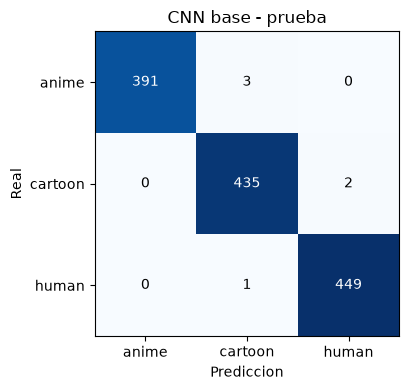

In [21]:
# Evaluacion de la CNN base en prueba: conjunto que no se uso para entrenar ni para elegir hiperparametros.
# Se evalua una sola vez por modelo y no se usa para tomar decisiones de ajuste.
X_test, y_test = data["test"]
test_ds = make_ds(X_test, y_test)
y_pred_test = model.predict(test_ds, verbose=0).argmax(axis=1)
metrics_base_test = evaluate(y_test, y_pred_test, "CNN base - prueba")

## 7. Prueba con imagenes externas
Las metricas anteriores se calculan con imagenes del mismo dataset, que comparten sesgos con las de entrenamiento (resolucion, color, composicion). Para saber si el modelo generaliza, se evalua con imagenes que no pertenecen al dataset, guardadas en `imgExternas/`. La clase de cada una se deduce del prefijo de su nombre (`caricatura*` = cartoon, `pruebaAnime*` = anime, `pruebaPersona*` = human).

Antes de evaluar se compara cada imagen con las del dataset por contenido (MD5), y las que son copias se excluyen de la evaluacion externa: una imagen que el modelo pudo ver al entrenar no prueba la generalizacion. Se usa exactamente el mismo preprocesado que la interfaz web (`padding`).

Es un conjunto muy pequeno, asi que sirve para ver patrones y no para medir con precision.

In [22]:
EXT_DIR = ROOT / "imgExternas"
EXT_PREFIX = {"caricatura": "cartoon", "pruebaanime": "anime", "pruebapersona": "human"}   # prefijo del nombre -> clase


def ext_label(name):
    for prefix, label in EXT_PREFIX.items():
        if name.lower().startswith(prefix):
            return label
    raise ValueError(f"no se pudo deducir la clase de {name}")


ext_df = pd.DataFrame(
    [{"archivo": p.name, "filepath": str(p), "label": ext_label(p.name)}
     for p in sorted(EXT_DIR.iterdir()) if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
)
ext_df["md5"] = [hashlib.md5(Path(f).read_bytes()).hexdigest() for f in ext_df["filepath"]]

# Una imagen externa no puede ser copia de una del dataset
split_of = {h: name for name, d in splits.items() for h in d["md5"]}
ext_df["en_dataset"] = ext_df["md5"].isin(set(df["md5"]))
ext_df["particion"] = ext_df["md5"].map(split_of)
display(ext_df[["archivo", "label", "en_dataset", "particion"]])

ext_test = ext_df[~ext_df["en_dataset"]].reset_index(drop=True)
ext_copies = ext_df[ext_df["en_dataset"]].reset_index(drop=True)
print(f"Imagenes externas validas: {len(ext_test)} de {len(ext_df)} "
      f"(se excluyen {len(ext_copies)} copias del dataset)")
print(ext_test["label"].value_counts().to_string())

,archivo,label,en_dataset,particion
0,Caricaturas2.jpg,cartoon,False,NaN
1,caricatura1.jpg,cartoon,False,NaN
2,pruebaAnime.jpg,anime,False,NaN
3,pruebaAnime2.jpg,anime,False,NaN
4,pruebaAnime3.jpg,anime,False,NaN
5,pruebaAnime4.jpg,anime,True,train
6,pruebaAnime6.jpg,anime,False,NaN
7,pruebaPersona.jpg,human,False,NaN
8,pruebaPersona2.jpg,human,False,NaN
9,pruebaPersona3.png,human,True,train


Imagenes externas validas: 8 de 10 (se excluyen 2 copias del dataset)
label
anime      4
cartoon    2
human      2


,archivo,label,prediccion,confianza,correcta
0,Caricaturas2.jpg,cartoon,cartoon,100.0%,True
1,caricatura1.jpg,cartoon,cartoon,100.0%,True
2,pruebaAnime.jpg,anime,cartoon,100.0%,False
3,pruebaAnime2.jpg,anime,cartoon,100.0%,False
4,pruebaAnime3.jpg,anime,cartoon,100.0%,False
5,pruebaAnime6.jpg,anime,cartoon,100.0%,False
6,pruebaPersona.jpg,human,cartoon,100.0%,False
7,pruebaPersona2.jpg,human,cartoon,100.0%,False


Accuracy: 0.2500 | F1 macro: 0.1333

              precision    recall  f1-score   support

       anime      0.000     0.000     0.000         4
     cartoon      0.250     1.000     0.400         2
       human      0.000     0.000     0.000         2

    accuracy                          0.250         8
   macro avg      0.083     0.333     0.133         8
weighted avg      0.062     0.250     0.100         8



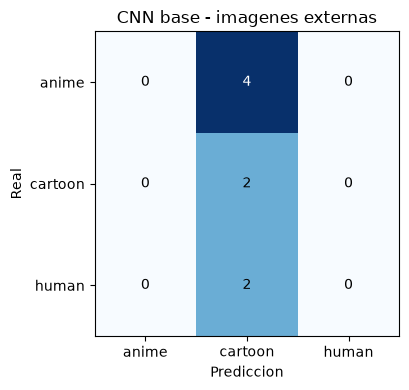

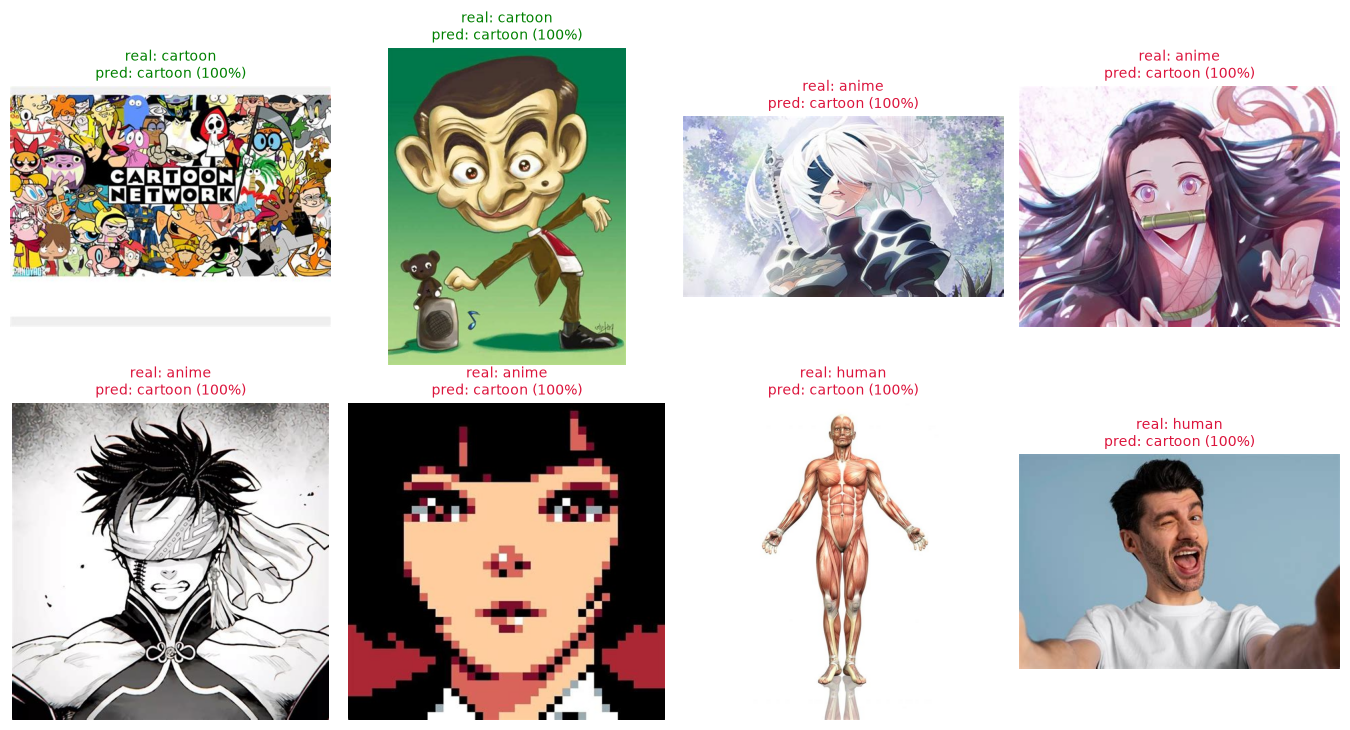


Control (copias del dataset, no cuentan como externas):


,archivo,label,particion,prediccion
0,pruebaAnime4.jpg,anime,train,anime
1,pruebaPersona3.png,human,train,human


In [23]:
def center_square(im):
    """Recorte cuadrado central (para probar sin barras de relleno)."""
    s = min(im.size)
    left, top = (im.width - s) // 2, (im.height - s) // 2
    return im.crop((left, top, left + s, top + s))


def predict_files(paths, mode="pad", crop=False, net=None):
    """Probabilidades de una red (por defecto la CNN base) para una lista de archivos, con el preprocesado del entrenamiento."""
    arrs = []
    for fp in paths:
        with Image.open(fp) as im:
            arrs.append(preprocess_image(center_square(im) if crop else im, IMG_SIZE, mode))
    return (model if net is None else net).predict(np.stack(arrs), verbose=0)


probs = predict_files(ext_test["filepath"])
ext_test["prediccion"] = [CLASSES[i] for i in probs.argmax(axis=1)]
ext_test["confianza"] = probs.max(axis=1)
ext_test["correcta"] = ext_test["label"] == ext_test["prediccion"]
display(ext_test[["archivo", "label", "prediccion", "confianza", "correcta"]].style.format({"confianza": "{:.1%}"}))

y_ext = ext_test["label"].map(CLASS_TO_IDX).to_numpy()
metrics_ext = evaluate(y_ext, probs.argmax(axis=1), "CNN base - imagenes externas")

# Figura para el reporte
cols = 4
rows = -(-len(ext_test) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.7 * rows))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, (_, r) in zip(np.ravel(axes), ext_test.iterrows()):
    with Image.open(r["filepath"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"real: {r['label']}\npred: {r['prediccion']} ({r['confianza']:.0%})",
                 color="green" if r["correcta"] else "crimson", fontsize=10)
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "externas.png", dpi=200, bbox_inches="tight")
plt.show()

# Control: las copias del dataset si deberian acertarse (el modelo pudo verlas)
if len(ext_copies):
    p_copies = predict_files(ext_copies["filepath"])
    ext_copies["prediccion"] = [CLASSES[i] for i in p_copies.argmax(axis=1)]
    print("\nControl (copias del dataset, no cuentan como externas):")
    display(ext_copies[["archivo", "label", "particion", "prediccion"]])

In [24]:
# Efecto del preprocesado: padding (como la web), estirada a cuadrado y recorte cuadrado central
variants = {
    "padding (web)": dict(mode="pad"),
    "estirada": dict(mode="stretch"),
    "recorte central": dict(mode="pad", crop=True),
}
table = ext_test[["archivo", "label"]].copy()
for name, kwargs in variants.items():
    table[name] = [CLASSES[i] for i in predict_files(ext_test["filepath"], **kwargs).argmax(axis=1)]
display(table)
for name in variants:
    print(f"{name:16s} exactitud: {(table[name] == table['label']).mean():.1%}")

,archivo,label,padding (web),estirada,recorte central
0,Caricaturas2.jpg,cartoon,cartoon,cartoon,cartoon
1,caricatura1.jpg,cartoon,cartoon,cartoon,cartoon
2,pruebaAnime.jpg,anime,cartoon,cartoon,cartoon
3,pruebaAnime2.jpg,anime,cartoon,cartoon,cartoon
4,pruebaAnime3.jpg,anime,cartoon,cartoon,cartoon
5,pruebaAnime6.jpg,anime,cartoon,cartoon,cartoon
6,pruebaPersona.jpg,human,cartoon,cartoon,cartoon
7,pruebaPersona2.jpg,human,cartoon,cartoon,cartoon


padding (web)    exactitud: 25.0%
estirada         exactitud: 25.0%
recorte central  exactitud: 25.0%


## 8. Transfer learning: EfficientNetB0
La CNN base se entreno desde cero y, aunque llega a 99.5% en prueba, solo acierta 2 de 8 imagenes externas. Se prueba ahora una red preentrenada con ImageNet, cuyas caracteristicas visuales ya incluyen muchos estilos, siguiendo la estrategia de ajustar solo las ultimas capas cuando el dataset es pequeno (Gando et al., 2016).

Para poder atribuir cualquier cambio a la red preentrenada, no se modifican los datos ni se agrega aumento de datos ni regularizacion adicional: se usan las mismas imagenes de 128x128 y las mismas particiones.

- **Red base:** `EfficientNetB0` sin su clasificador original (`include_top=False`), con pesos de ImageNet. Incluye su propio preprocesado y espera pixeles en [0, 255], por lo que **no** se divide entre 255.
- **Cabeza nueva:** `GlobalAveragePooling2D` y `Dense(3, softmax)`.
- **Fase 1 (cabeza):** base congelada, solo se entrena la cabeza. Adam con tasa de aprendizaje 0.001, 8 epocas.
- **Fase 2 (ajuste fino):** se descongelan las ultimas 20 capas de la base, manteniendo congeladas las capas `BatchNormalization`. Adam con tasa de aprendizaje 0.00001, 10 epocas.

El modelo final y su historial se guardan en `modelos/`.

In [25]:
EPOCHS_HEAD = 8
EPOCHS_FINE = 10
FINE_TUNE_LAYERS = 20
TL_NAME = f"efficientnetb0_{RESIZE_MODE}"


def build_transfer(dropout=0.0, name="efficientnetb0_transfer"):
    """EfficientNetB0 preentrenada (congelada) con una cabeza de clasificacion nueva (con Dropout si dropout > 0)."""
    base = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base(inputs, training=False)   # la normalizacion por lote se mantiene en modo inferencia
    x = keras.layers.GlobalAveragePooling2D()(x)
    if dropout:
        x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name), base


def compile_tl(net, lr):
    net.compile(optimizer=keras.optimizers.Adam(lr),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])


tl_model, tl_base = build_transfer()
compile_tl(tl_model, 1e-3)
print(f"Parametros de la base: {tl_base.count_params():,} | entrenables en la fase 1: "
      f"{sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights):,}")

Parametros de la base: 4,049,571 | entrenables en la fase 1: 3,843


In [26]:
tl_path = MODELS_DIR / f"{TL_NAME}.keras"
tl_history_path = MODELS_DIR / f"{TL_NAME}_history.json"
RETRAIN_TL = False   # True: volver a entrenar aunque ya exista el modelo guardado

if tl_path.exists() and not RETRAIN_TL:
    tl_model = keras.models.load_model(tl_path, compile=False)
    tl_history = json.loads(tl_history_path.read_text())
    print("Modelo cargado de", tl_path.relative_to(ROOT))
else:
    keras.utils.set_random_seed(SEED)
    tl_model, tl_base = build_transfer()

    # Fase 1: solo la cabeza
    compile_tl(tl_model, 1e-3)
    fit_head = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, shuffle=False, verbose=2)

    # Fase 2: ajuste fino de las ultimas capas de la base (sin tocar BatchNormalization)
    tl_base.trainable = True
    for layer in tl_base.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in tl_base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    compile_tl(tl_model, 1e-5)
    print(f"Fase 2 - parametros entrenables: {sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights):,}")
    fit_fine = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, shuffle=False, verbose=2)

    tl_history = {"head": fit_head.history, "fine_tuning": fit_fine.history}
    compile_tl(tl_model, 1e-5)   # optimizador nuevo sin estado: el archivo pesa menos
    tl_model.save(tl_path)
    tl_history_path.write_text(json.dumps(tl_history))
    print("Modelo guardado en", tl_path.relative_to(ROOT))

Modelo cargado de modelos/efficientnetb0_pad.keras


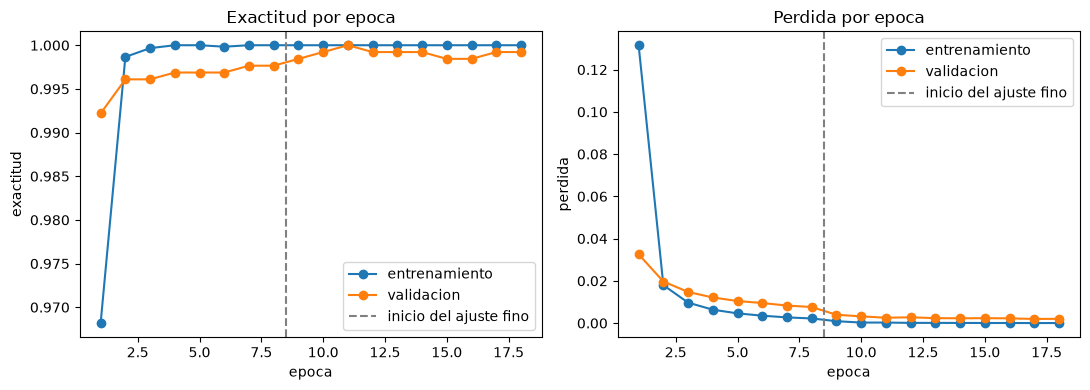

In [27]:
# Curvas de aprendizaje de las dos fases
head, fine = tl_history["head"], tl_history["fine_tuning"]
boundary = len(head["loss"])
epochs_range = range(1, boundary + len(fine["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["accuracy", "loss"], ["Exactitud", "Perdida"]):
    ax.plot(epochs_range, head[metric] + fine[metric], marker="o", label="entrenamiento")
    ax.plot(epochs_range, head[f"val_{metric}"] + fine[f"val_{metric}"], marker="o", label="validacion")
    ax.axvline(boundary + 0.5, color="gray", linestyle="--", label="inicio del ajuste fino")
    ax.set_title(f"{title} por epoca")
    ax.set_xlabel("epoca")
    ax.set_ylabel(title.lower())
    ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "curvas_efficientnet.png", dpi=200, bbox_inches="tight")
plt.show()

Accuracy: 0.9992 | F1 macro: 0.9992

              precision    recall  f1-score   support

       anime      0.997     1.000     0.999       393
     cartoon      1.000     0.998     0.999       437
       human      1.000     1.000     1.000       450

    accuracy                          0.999      1280
   macro avg      0.999     0.999     0.999      1280
weighted avg      0.999     0.999     0.999      1280



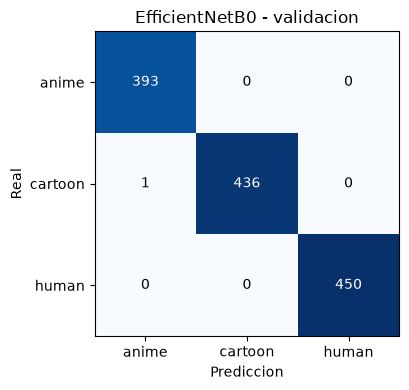

In [28]:
# Evaluacion en validacion
y_pred_val_tl = tl_model.predict(val_ds, verbose=0).argmax(axis=1)
metrics_tl_val = evaluate(y_val, y_pred_val_tl, "EfficientNetB0 - validacion")

Accuracy: 0.9992 | F1 macro: 0.9992

              precision    recall  f1-score   support

       anime      1.000     1.000     1.000       394
     cartoon      0.998     1.000     0.999       437
       human      1.000     0.998     0.999       450

    accuracy                          0.999      1281
   macro avg      0.999     0.999     0.999      1281
weighted avg      0.999     0.999     0.999      1281



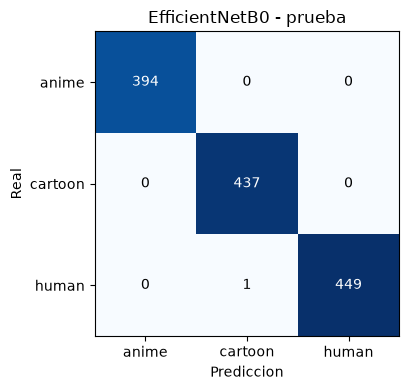

In [29]:
# Evaluacion en prueba (una sola vez para este modelo)
y_pred_test_tl = tl_model.predict(test_ds, verbose=0).argmax(axis=1)
metrics_tl_test = evaluate(y_test, y_pred_test_tl, "EfficientNetB0 - prueba")

,archivo,label,prediccion,confianza,correcta
0,Caricaturas2.jpg,cartoon,cartoon,100.0%,True
1,caricatura1.jpg,cartoon,cartoon,100.0%,True
2,pruebaAnime.jpg,anime,cartoon,100.0%,False
3,pruebaAnime2.jpg,anime,cartoon,100.0%,False
4,pruebaAnime3.jpg,anime,cartoon,94.4%,False
5,pruebaAnime6.jpg,anime,anime,97.1%,True
6,pruebaPersona.jpg,human,cartoon,97.6%,False
7,pruebaPersona2.jpg,human,human,80.7%,True


Accuracy: 0.5000 | F1 macro: 0.5222

              precision    recall  f1-score   support

       anime      1.000     0.250     0.400         4
     cartoon      0.333     1.000     0.500         2
       human      1.000     0.500     0.667         2

    accuracy                          0.500         8
   macro avg      0.778     0.583     0.522         8
weighted avg      0.833     0.500     0.492         8



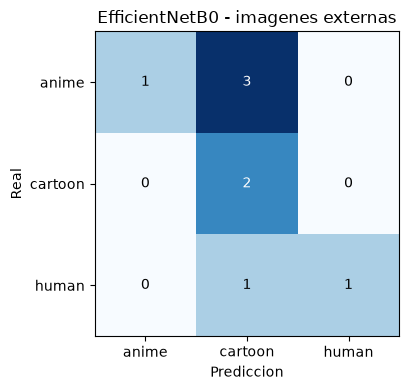

In [30]:
# Evaluacion con las imagenes externas
probs_tl = predict_files(ext_test["filepath"], net=tl_model)
ext_tl = ext_test[["archivo", "label"]].copy()
ext_tl["prediccion"] = [CLASSES[i] for i in probs_tl.argmax(axis=1)]
ext_tl["confianza"] = probs_tl.max(axis=1)
ext_tl["correcta"] = ext_tl["label"] == ext_tl["prediccion"]
display(ext_tl.style.format({"confianza": "{:.1%}"}))
metrics_tl_ext = evaluate(y_ext, probs_tl.argmax(axis=1), "EfficientNetB0 - imagenes externas")

In [31]:
# Comparacion entre modelos
comparison = pd.DataFrame({
    "CNN base": (metrics_base_val, metrics_base_test, metrics_ext),
    "EfficientNetB0": (metrics_tl_val, metrics_tl_test, metrics_tl_ext),
}, index=["validacion", "prueba", "externas"]).T
comparison = pd.concat({m: comparison[m].apply(pd.Series) for m in comparison.columns}, axis=1)
display(comparison.rename(columns={"accuracy": "exactitud", "f1_macro": "F1 macro"}).style.format("{:.4f}"))

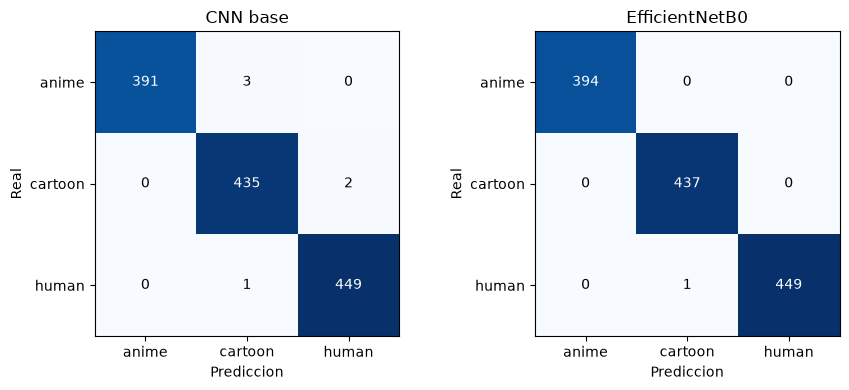

In [32]:
# Matrices de confusion en prueba, lado a lado (para el reporte)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, pred) in zip(axes, [("CNN base", y_pred_test), ("EfficientNetB0", y_pred_test_tl)]):
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Real")
    ax.set_title(name)
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "matrices_prueba.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Regularizacion: Dropout
Ninguno de los modelos anteriores tiene regularizacion explicita. Dropout (Srivastava et al., 2014) apaga al azar una fraccion de las neuronas en cada paso de entrenamiento, lo que obliga a la red a no depender de neuronas individuales y reduce la coadaptacion entre ellas. Solo actua al entrenar: en la prediccion se usan todas las neuronas.

Se prueba por separado en cada arquitectura, con una sola tasa por modelo y sin ajustarla, para no sobreajustar a un conjunto externo tan pequeno:
- **CNN + Dropout:** `Dropout(0.5)` despues de la capa densa de 128 neuronas, que concentra el 97% de los parametros de la red. 0.5 es el valor habitual para capas densas.
- **EfficientNetB0 + Dropout:** `Dropout(0.2)` despues del `GlobalAveragePooling2D`, la misma tasa que usa el clasificador original de EfficientNetB0.

Todo lo demas (datos, particiones, epocas, tasas de aprendizaje y fases de entrenamiento) es igual que en los modelos sin Dropout, para que la unica diferencia sea esa. Como en los modelos anteriores la exactitud de entrenamiento y la de validacion son casi iguales, no se espera una gran mejora; se evalua de todas formas, tambien con las imagenes externas.

In [33]:
DROPOUT_CNN = 0.5
DROPOUT_TL = 0.2

cnn_do_path = MODELS_DIR / f"cnn_dropout_{RESIZE_MODE}.keras"
cnn_do_history_path = MODELS_DIR / f"cnn_dropout_{RESIZE_MODE}_history.json"
RETRAIN_CNN_DO = False   # True: volver a entrenar aunque ya exista el modelo guardado

if cnn_do_path.exists() and not RETRAIN_CNN_DO:
    cnn_do = keras.models.load_model(cnn_do_path, compile=False)
    cnn_do_history = json.loads(cnn_do_history_path.read_text())
    print("Modelo cargado de", cnn_do_path.relative_to(ROOT))
else:
    keras.utils.set_random_seed(SEED)
    cnn_do = build_cnn_base(dropout=DROPOUT_CNN, name="cnn_dropout")
    cnn_do.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    fit_cnn_do = cnn_do.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, shuffle=False, verbose=2)
    cnn_do_history = fit_cnn_do.history
    cnn_do.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])   # optimizador sin estado
    cnn_do.save(cnn_do_path)
    cnn_do_history_path.write_text(json.dumps(cnn_do_history))
    print("Modelo guardado en", cnn_do_path.relative_to(ROOT))

Modelo cargado de modelos/cnn_dropout_pad.keras


In [34]:
tl_do_path = MODELS_DIR / f"efficientnetb0_dropout_{RESIZE_MODE}.keras"
tl_do_history_path = MODELS_DIR / f"efficientnetb0_dropout_{RESIZE_MODE}_history.json"
RETRAIN_TL_DO = False   # True: volver a entrenar aunque ya exista el modelo guardado

if tl_do_path.exists() and not RETRAIN_TL_DO:
    tl_do = keras.models.load_model(tl_do_path, compile=False)
    tl_do_history = json.loads(tl_do_history_path.read_text())
    print("Modelo cargado de", tl_do_path.relative_to(ROOT))
else:
    keras.utils.set_random_seed(SEED)
    tl_do, tl_do_base = build_transfer(dropout=DROPOUT_TL, name="efficientnetb0_dropout")

    # Fase 1: solo la cabeza (con Dropout)
    compile_tl(tl_do, 1e-3)
    fit_do_head = tl_do.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, shuffle=False, verbose=2)

    # Fase 2: ajuste fino de las ultimas capas, igual que en el modelo sin Dropout
    tl_do_base.trainable = True
    for layer in tl_do_base.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in tl_do_base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    compile_tl(tl_do, 1e-5)
    fit_do_fine = tl_do.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, shuffle=False, verbose=2)

    tl_do_history = {"head": fit_do_head.history, "fine_tuning": fit_do_fine.history}
    compile_tl(tl_do, 1e-5)   # optimizador sin estado: el archivo pesa menos
    tl_do.save(tl_do_path)
    tl_do_history_path.write_text(json.dumps(tl_do_history))
    print("Modelo guardado en", tl_do_path.relative_to(ROOT))

Modelo cargado de modelos/efficientnetb0_dropout_pad.keras


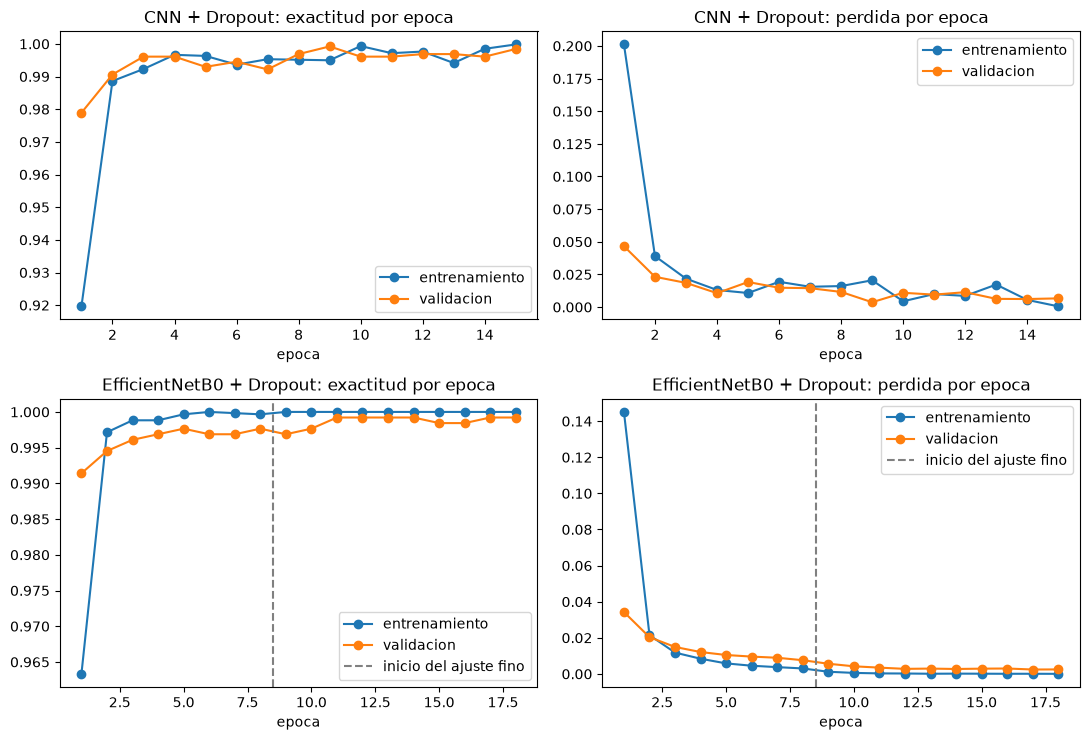

In [35]:
# Curvas de aprendizaje de los dos modelos con Dropout
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

epochs_cnn = range(1, len(cnn_do_history["loss"]) + 1)
for ax, metric, title in zip(axes[0], ["accuracy", "loss"], ["exactitud", "perdida"]):
    ax.plot(epochs_cnn, cnn_do_history[metric], marker="o", label="entrenamiento")
    ax.plot(epochs_cnn, cnn_do_history[f"val_{metric}"], marker="o", label="validacion")
    ax.set_title(f"CNN + Dropout: {title} por epoca")
    ax.set_xlabel("epoca")
    ax.legend()

h, f = tl_do_history["head"], tl_do_history["fine_tuning"]
boundary = len(h["loss"])
epochs_tl = range(1, boundary + len(f["loss"]) + 1)
for ax, metric, title in zip(axes[1], ["accuracy", "loss"], ["exactitud", "perdida"]):
    ax.plot(epochs_tl, h[metric] + f[metric], marker="o", label="entrenamiento")
    ax.plot(epochs_tl, h[f"val_{metric}"] + f[f"val_{metric}"], marker="o", label="validacion")
    ax.axvline(boundary + 0.5, color="gray", linestyle="--", label="inicio del ajuste fino")
    ax.set_title(f"EfficientNetB0 + Dropout: {title} por epoca")
    ax.set_xlabel("epoca")
    ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "curvas_dropout.png", dpi=200, bbox_inches="tight")
plt.show()

In [36]:
# Evaluacion de los modelos con Dropout en validacion, prueba (una sola vez) e imagenes externas
def quick_metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)}


reg = {}
for name, net in {"CNN + Dropout": cnn_do, "EfficientNetB0 + Dropout": tl_do}.items():
    p_val = net.predict(val_ds, verbose=0).argmax(axis=1)
    p_test = net.predict(test_ds, verbose=0).argmax(axis=1)
    p_ext = predict_files(ext_test["filepath"], net=net)
    reg[name] = {"val": quick_metrics(y_val, p_val), "test": quick_metrics(y_test, p_test),
                 "ext": quick_metrics(y_ext, p_ext.argmax(axis=1)), "pred_test": p_test, "probs_ext": p_ext}

summary = {
    "CNN base": (metrics_base_val, metrics_base_test, metrics_ext, y_pred_test),
    "CNN + Dropout": (*[reg["CNN + Dropout"][k] for k in ("val", "test", "ext")], reg["CNN + Dropout"]["pred_test"]),
    "EfficientNetB0": (metrics_tl_val, metrics_tl_test, metrics_tl_ext, y_pred_test_tl),
    "EfficientNetB0 + Dropout": (*[reg["EfficientNetB0 + Dropout"][k] for k in ("val", "test", "ext")],
                                 reg["EfficientNetB0 + Dropout"]["pred_test"]),
}
rows = {}
for name, (v, t, e, p_test) in summary.items():
    rows[name] = {("validacion", "exactitud"): v["accuracy"], ("validacion", "F1 macro"): v["f1_macro"],
                  ("prueba", "exactitud"): t["accuracy"], ("prueba", "F1 macro"): t["f1_macro"],
                  ("prueba", "errores"): int((p_test != y_test).sum()),
                  ("externas", "exactitud"): e["accuracy"], ("externas", "F1 macro"): e["f1_macro"]}
comparison4 = pd.DataFrame(rows).T
formats = {col: "{:.4f}" for col in comparison4.columns if col[1] != "errores"}
formats[("prueba", "errores")] = "{:.0f}"
display(comparison4.style.format(formats))

In [37]:
# Predicciones por imagen externa de los cuatro modelos: clase (confianza)
def fmt(labels, confidences):
    return [f"{l} ({c:.0%})" for l, c in zip(labels, confidences)]


ext_all = ext_test[["archivo", "label"]].copy()
ext_all["CNN base"] = fmt(ext_test["prediccion"], ext_test["confianza"])
for name, col in [("CNN + Dropout", "CNN + Dropout"), ("EfficientNetB0 + Dropout", "EfficientNetB0 + Dropout")]:
    pr = reg[name]["probs_ext"]
    ext_all[col] = fmt([CLASSES[i] for i in pr.argmax(axis=1)], pr.max(axis=1))
ext_all.insert(3, "EfficientNetB0", fmt(ext_tl["prediccion"], ext_tl["confianza"]))
ext_all = ext_all[["archivo", "label", "CNN base", "CNN + Dropout", "EfficientNetB0", "EfficientNetB0 + Dropout"]]
display(ext_all)

,archivo,label,CNN base,CNN + Dropout,EfficientNetB0,EfficientNetB0 + Dropout
0,Caricaturas2.jpg,cartoon,cartoon (100%),cartoon (100%),cartoon (100%),cartoon (100%)
1,caricatura1.jpg,cartoon,cartoon (100%),cartoon (100%),cartoon (100%),cartoon (100%)
2,pruebaAnime.jpg,anime,cartoon (100%),cartoon (100%),cartoon (100%),cartoon (100%)
3,pruebaAnime2.jpg,anime,cartoon (100%),cartoon (100%),cartoon (100%),cartoon (100%)
4,pruebaAnime3.jpg,anime,cartoon (100%),cartoon (100%),cartoon (94%),cartoon (98%)
5,pruebaAnime6.jpg,anime,cartoon (100%),cartoon (100%),anime (97%),anime (99%)
6,pruebaPersona.jpg,human,cartoon (100%),cartoon (100%),cartoon (98%),cartoon (97%)
7,pruebaPersona2.jpg,human,cartoon (100%),cartoon (100%),human (81%),human (82%)


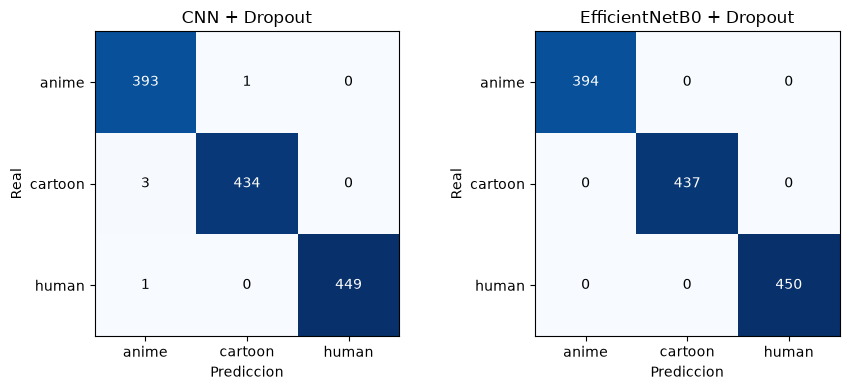

In [38]:
# Matrices de confusion en prueba de los dos modelos con Dropout (para el reporte)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["CNN + Dropout", "EfficientNetB0 + Dropout"]):
    cm = confusion_matrix(y_test, reg[name]["pred_test"], labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Real")
    ax.set_title(name)
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "matrices_dropout.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Tratamiento de los datos: estirar y aumento de datos
Hasta aqui los modelos se entrenaron con las imagenes con padding y sin aumento de datos. Los experimentos con imagenes externas sugieren que el problema no es el modelo sino la poca diversidad de los datos de entrenamiento, asi que se cambia el tratamiento de los datos. Son dos cambios, y para poder explicar cual funciona se prueban por separado y juntos, siempre con EfficientNetB0 (el mejor modelo hasta ahora, sin Dropout) y el mismo entrenamiento en dos fases:

| Variante | Redimensionado | Aumento de datos |
|---|---|---|
| EfficientNetB0 (seccion 8) | padding | no |
| `stretch` | **estirar** a cuadrado | no |
| `pad_aug` | padding | **si** |
| `stretch_aug` | **estirar** a cuadrado | **si** |

- **Estirar:** elimina las barras de relleno, que solo aparecian en las cartoon no cuadradas y podian actuar como atajo. A cambio, deforma las imagenes no cuadradas.
- **Aumento de datos** (solo en entrenamiento, imagen por imagen y distinto en cada epoca): volteo horizontal, rotacion de hasta 11 grados, zoom de 25% con proporcion variable, traslacion de 10%, cambios de brillo, contraste y saturacion, escala de grises (15% de las veces) y baja resolucion (50% de las veces, reduciendo la imagen y volviendola a ampliar). Estan pensados para atacar los atajos del analisis exploratorio: composicion y proporcion, color y nitidez.

La validacion y la prueba no llevan aumento. Cada modelo se evalua con el mismo preprocesado con que se entreno, y el conjunto de prueba se evalua una sola vez por modelo.

stretch train X=(5973, 128, 128, 3) uint8 | clases=[1834, 2039, 2100]
stretch val   X=(1280, 128, 128, 3) uint8 | clases=[393, 437, 450]
stretch test  X=(1281, 128, 128, 3) uint8 | clases=[394, 437, 450]


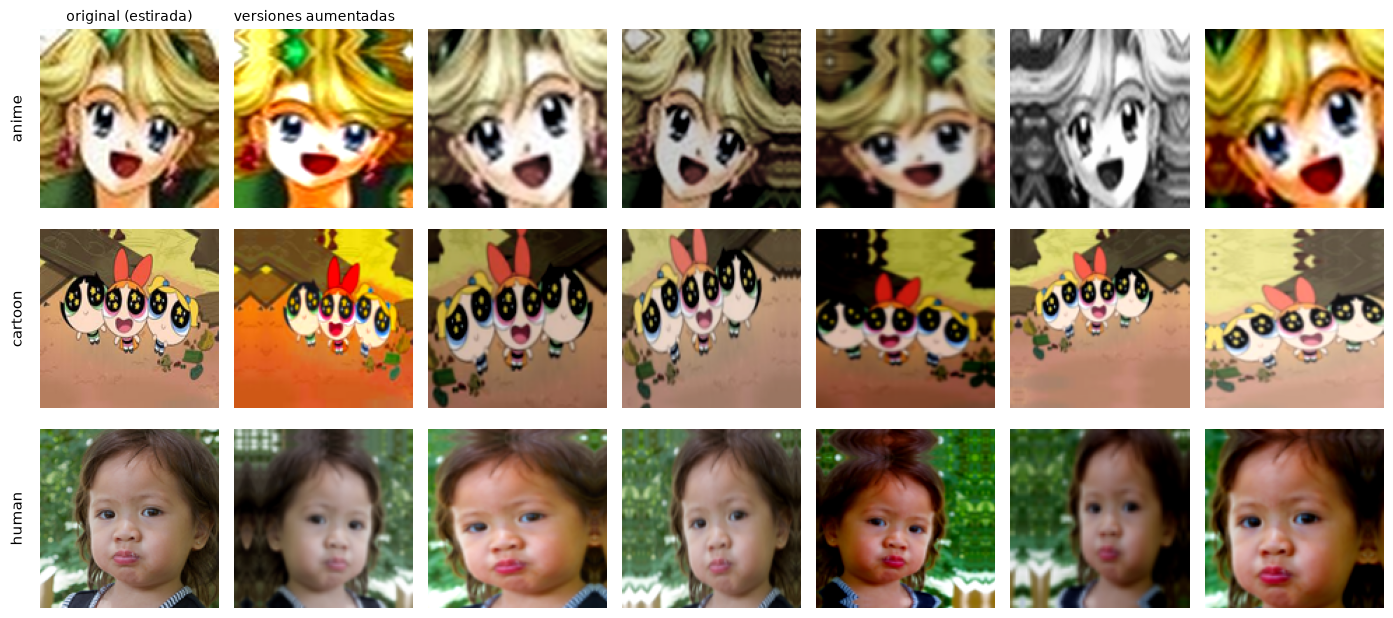

In [39]:
AUGMENT_PIPELINE = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.03, fill_mode="reflect"),                       # +-11 grados
    keras.layers.RandomZoom(height_factor=(-0.25, 0.25), width_factor=(-0.25, 0.25),
                            fill_mode="reflect"),                                 # escala y proporcion
    keras.layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    keras.layers.RandomColorJitter(value_range=(0, 255), brightness_factor=0.25,
                                   contrast_factor=0.3, saturation_factor=(0.3, 0.7)),   # 0.5 = sin cambio
], name="aumento_de_datos")


def augment(x, y):
    """Aumento de datos de una imagen (0-255): geometria, color, escala de grises y baja resolucion."""
    x = AUGMENT_PIPELINE(tf.cast(x, tf.float32), training=True)
    # a veces en escala de grises (manga, fotos antiguas)
    x = tf.cond(tf.random.uniform(()) < 0.15,
                lambda: tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x)), lambda: x)
    # a veces con baja resolucion (reduce y vuelve a ampliar), para que la nitidez no delate la clase
    def degrade():
        side = tf.cast(IMG_SIZE * tf.random.uniform((), 0.35, 1.0), tf.int32)
        small = tf.image.resize(x, (side, side), method="bilinear", antialias=True)
        return tf.image.resize(small, (IMG_SIZE, IMG_SIZE), method="bilinear")
    x = tf.cond(tf.random.uniform(()) < 0.5, degrade, lambda: x)
    return tf.clip_by_value(x, 0.0, 255.0), y


def make_ds_aug(X, y):
    """Dataset de entrenamiento con aumento de datos (se aplica imagen por imagen, antes de agrupar)."""
    ds = tf.data.Dataset.from_tensor_slices((X, y)).shuffle(len(X), seed=SEED)
    return ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


data_stretch = {name: build_split(name, d, "stretch") for name, d in splits.items()}
for name, (X, y) in data_stretch.items():
    print(f"stretch {name:5s} X={X.shape} {X.dtype} | clases={np.bincount(y).tolist()}")

X_tr_pad, y_tr_pad = data["train"]
X_tr_st, y_tr_st = data_stretch["train"]
val_ds_st = make_ds(*data_stretch["val"])
test_ds_st = make_ds(*data_stretch["test"])

# Ejemplos de aumento de datos (para el reporte): una imagen de cada clase, original y 6 versiones
rng = np.random.default_rng(1)
fig, axes = plt.subplots(len(CLASSES), 7, figsize=(14, 6.4))
for r, c in enumerate(CLASSES):
    i = rng.choice(np.where(y_tr_st == CLASS_TO_IDX[c])[0])
    axes[r, 0].imshow(X_tr_st[i])
    axes[r, 0].text(-0.08, 0.5, c, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11)
    for k in range(1, 7):
        axes[r, k].imshow(augment(X_tr_st[i], y_tr_st[i])[0].numpy().astype("uint8"))
axes[0, 0].set_title("original (estirada)", fontsize=10)
axes[0, 1].set_title("versiones aumentadas", fontsize=10, loc="left")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "aumento_datos.png", dpi=200, bbox_inches="tight")
plt.show()

In [40]:
def train_or_load_transfer(tag, train_data, val_data, retrain=False):
    """EfficientNetB0 en dos fases (igual que en la seccion 8) con los datos indicados; guarda o carga el modelo."""
    path = MODELS_DIR / f"efficientnetb0_{tag}.keras"
    history_path = MODELS_DIR / f"efficientnetb0_{tag}_history.json"
    if path.exists() and not retrain:
        print("Modelo cargado de", path.relative_to(ROOT))
        return keras.models.load_model(path, compile=False), json.loads(history_path.read_text())

    keras.utils.set_random_seed(SEED)
    net, base = build_transfer(name=f"efficientnetb0_{tag}")
    compile_tl(net, 1e-3)
    fit_head = net.fit(train_data, validation_data=val_data, epochs=EPOCHS_HEAD, shuffle=False, verbose=2)

    base.trainable = True
    for layer in base.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    compile_tl(net, 1e-5)
    fit_fine = net.fit(train_data, validation_data=val_data, epochs=EPOCHS_FINE, shuffle=False, verbose=2)

    history = {"head": fit_head.history, "fine_tuning": fit_fine.history}
    compile_tl(net, 1e-5)   # optimizador sin estado: el archivo pesa menos
    net.save(path)
    history_path.write_text(json.dumps(history))
    print("Modelo guardado en", path.relative_to(ROOT))
    return net, history


train_ds_st = make_ds(X_tr_st, y_tr_st, shuffle=True)    # estirar, sin aumento
train_ds_pad_aug = make_ds_aug(X_tr_pad, y_tr_pad)        # padding, con aumento
train_ds_st_aug = make_ds_aug(X_tr_st, y_tr_st)           # estirar, con aumento

In [41]:
# Variante `stretch`: estirar, sin aumento de datos
tl_st, hist_st = train_or_load_transfer("stretch", train_ds_st, val_ds_st)

Epoch 1/8


187/187 - 19s - 104ms/step - accuracy: 0.9613 - loss: 0.1453 - val_accuracy: 0.9867 - val_loss: 0.0419


Epoch 2/8


187/187 - 15s - 82ms/step - accuracy: 0.9972 - loss: 0.0232 - val_accuracy: 0.9898 - val_loss: 0.0267


Epoch 3/8


187/187 - 15s - 81ms/step - accuracy: 0.9988 - loss: 0.0130 - val_accuracy: 0.9937 - val_loss: 0.0210


... (27 outputs left out)

187/187 - 22s - 118ms/step - accuracy: 1.0000 - loss: 4.5831e-05 - val_accuracy: 0.9969 - val_loss: 0.0070


Epoch 10/10


187/187 - 21s - 111ms/step - accuracy: 1.0000 - loss: 4.0255e-05 - val_accuracy: 0.9969 - val_loss: 0.0067


Modelo guardado en modelos/efficientnetb0_stretch.keras


In [42]:
# Variante `pad_aug`: padding, con aumento de datos
tl_pad_aug, hist_pad_aug = train_or_load_transfer("pad_aug", train_ds_pad_aug, val_ds)

Epoch 1/8


187/187 - 27s - 144ms/step - accuracy: 0.9508 - loss: 0.1779 - val_accuracy: 0.9836 - val_loss: 0.0560


Epoch 2/8


187/187 - 24s - 126ms/step - accuracy: 0.9903 - loss: 0.0408 - val_accuracy: 0.9891 - val_loss: 0.0356


Epoch 3/8


187/187 - 23s - 124ms/step - accuracy: 0.9940 - loss: 0.0284 - val_accuracy: 0.9906 - val_loss: 0.0284


... (27 outputs left out)

187/187 - 28s - 148ms/step - accuracy: 0.9982 - loss: 0.0054 - val_accuracy: 0.9969 - val_loss: 0.0090


Epoch 10/10


187/187 - 28s - 151ms/step - accuracy: 0.9987 - loss: 0.0046 - val_accuracy: 0.9969 - val_loss: 0.0095


Modelo guardado en modelos/efficientnetb0_pad_aug.keras


In [43]:
# Variante `stretch_aug`: estirar, con aumento de datos
tl_st_aug, hist_st_aug = train_or_load_transfer("stretch_aug", train_ds_st_aug, val_ds_st)

Epoch 1/8


187/187 - 31s - 164ms/step - accuracy: 0.9417 - loss: 0.2004 - val_accuracy: 0.9789 - val_loss: 0.0667


Epoch 2/8


187/187 - 27s - 143ms/step - accuracy: 0.9866 - loss: 0.0571 - val_accuracy: 0.9844 - val_loss: 0.0495


Epoch 3/8


187/187 - 28s - 149ms/step - accuracy: 0.9896 - loss: 0.0398 - val_accuracy: 0.9883 - val_loss: 0.0350


... (27 outputs left out)

187/187 - 29s - 156ms/step - accuracy: 0.9977 - loss: 0.0074 - val_accuracy: 0.9953 - val_loss: 0.0121


Epoch 10/10


187/187 - 30s - 158ms/step - accuracy: 0.9975 - loss: 0.0091 - val_accuracy: 0.9969 - val_loss: 0.0105


Modelo guardado en modelos/efficientnetb0_stretch_aug.keras


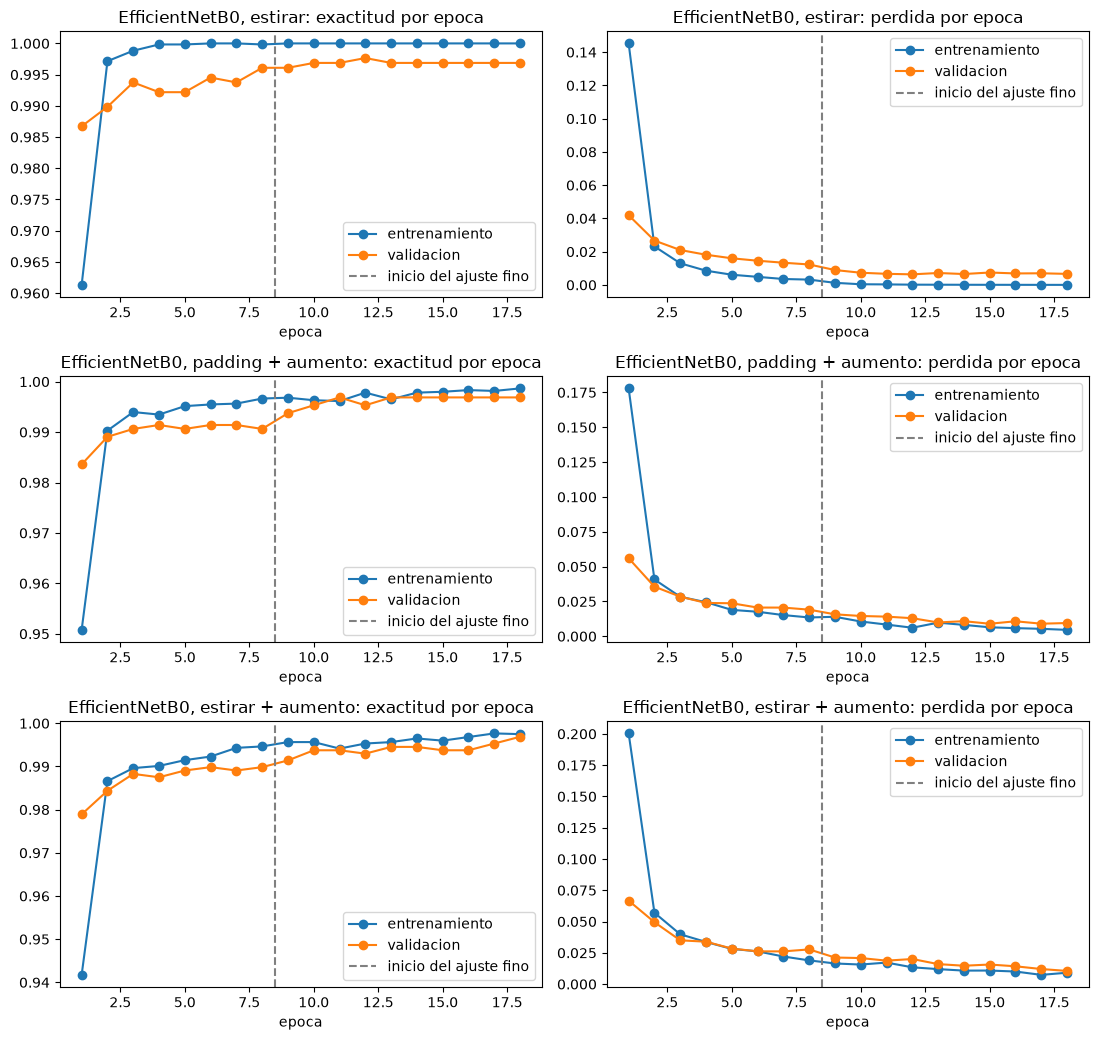

In [44]:
# Curvas de aprendizaje de las tres variantes
fig, axes = plt.subplots(3, 2, figsize=(11, 10.5))
for row, (title, hist) in zip(axes, [("estirar", hist_st), ("padding + aumento", hist_pad_aug),
                                     ("estirar + aumento", hist_st_aug)]):
    h, f = hist["head"], hist["fine_tuning"]
    boundary = len(h["loss"])
    epochs_range = range(1, boundary + len(f["loss"]) + 1)
    for ax, metric, name in zip(row, ["accuracy", "loss"], ["exactitud", "perdida"]):
        ax.plot(epochs_range, h[metric] + f[metric], marker="o", label="entrenamiento")
        ax.plot(epochs_range, h[f"val_{metric}"] + f[f"val_{metric}"], marker="o", label="validacion")
        ax.axvline(boundary + 0.5, color="gray", linestyle="--", label="inicio del ajuste fino")
        ax.set_title(f"EfficientNetB0, {title}: {name} por epoca")
        ax.set_xlabel("epoca")
        ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "docs" / "figuras" / "curvas_datos.png", dpi=200, bbox_inches="tight")
plt.show()

In [45]:
# Evaluacion de las cuatro variantes: validacion, prueba (una sola vez) e imagenes externas.
# Cada modelo se evalua con el mismo redimensionado con que se entreno.
data_variants = {
    "EfficientNetB0 (padding)": (tl_model, "pad", val_ds, test_ds),
    "+ estirar": (tl_st, "stretch", val_ds_st, test_ds_st),
    "+ aumento (padding)": (tl_pad_aug, "pad", val_ds, test_ds),
    "+ estirar y aumento": (tl_st_aug, "stretch", val_ds_st, test_ds_st),
}
res = {}
for name, (net, mode, v_ds, t_ds) in data_variants.items():
    p_val = net.predict(v_ds, verbose=0).argmax(axis=1)
    p_test = net.predict(t_ds, verbose=0).argmax(axis=1)
    p_ext = predict_files(ext_test["filepath"], mode=mode, net=net)
    res[name] = {"val": quick_metrics(y_val, p_val), "test": quick_metrics(y_test, p_test),
                 "ext": quick_metrics(y_ext, p_ext.argmax(axis=1)), "errors": int((p_test != y_test).sum()),
                 "probs_ext": p_ext}

rows = {n: {("validacion", "exactitud"): r["val"]["accuracy"], ("validacion", "F1 macro"): r["val"]["f1_macro"],
            ("prueba", "exactitud"): r["test"]["accuracy"], ("prueba", "F1 macro"): r["test"]["f1_macro"],
            ("prueba", "errores"): r["errors"],
            ("externas", "exactitud"): r["ext"]["accuracy"], ("externas", "F1 macro"): r["ext"]["f1_macro"]}
        for n, r in res.items()}
table_data = pd.DataFrame(rows).T
formats = {col: "{:.4f}" for col in table_data.columns if col[1] != "errores"}
formats[("prueba", "errores")] = "{:.0f}"
display(table_data.style.format(formats))

# Predicciones por imagen externa: clase (confianza)
ext_data = ext_test[["archivo", "label"]].copy()
for name, r in res.items():
    pr = r["probs_ext"]
    ext_data[name] = [f"{CLASSES[i]} ({p:.0%})" for i, p in zip(pr.argmax(axis=1), pr.max(axis=1))]
display(ext_data)

,archivo,label,EfficientNetB0 (padding),+ estirar,+ aumento (padding),+ estirar y aumento
0,Caricaturas2.jpg,cartoon,cartoon (100%),cartoon (100%),cartoon (100%),cartoon (100%)
1,caricatura1.jpg,cartoon,cartoon (100%),cartoon (100%),cartoon (100%),cartoon (99%)
2,pruebaAnime.jpg,anime,cartoon (100%),cartoon (90%),cartoon (91%),cartoon (85%)
3,pruebaAnime2.jpg,anime,cartoon (100%),cartoon (84%),cartoon (91%),cartoon (54%)
4,pruebaAnime3.jpg,anime,cartoon (94%),cartoon (99%),anime (91%),anime (69%)
5,pruebaAnime6.jpg,anime,anime (97%),anime (89%),anime (87%),anime (95%)
6,pruebaPersona.jpg,human,cartoon (98%),cartoon (100%),cartoon (99%),cartoon (100%)
7,pruebaPersona2.jpg,human,human (81%),human (100%),human (84%),human (96%)
